# 06 — Chọn đặc trưng và cửa sổ thời gian

Chọn đầu vào bằng GRU nhỏ trên **ba fold trong Train**. Mỗi fold có inner validation riêng để chọn epoch.
Chỉ dùng phần Train, không chạm Validation hay Test.

## Cách chọn

1. So sánh **9 bộ đặc trưng** (A–I) ở cùng window 48 giờ.
2. Thử **thêm** từng nhóm đặc trưng còn thiếu, giữ khi MAE giảm ít nhất 0.05 µg/m³.
3. Thử **bỏ** từng nhóm đã có, bỏ nếu không làm MAE xấu đi.
4. Chọn **cửa sổ lịch sử** tốt nhất trong [24, 48, 72, 96] giờ.

**Đầu vào:** `data/processed/feature_data.csv`
**Đầu ra:** `results/feature_selection/feature_config.json`

## I. Import thư viện

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import random
import gc
import json
import os
from sklearn.preprocessing import StandardScaler
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data' / 'processed'
RESULT_DIR = ROOT / 'results'

print('GPU:', tf.config.list_physical_devices('GPU'))
print('Thư mục dữ liệu:', DATA_DIR)

## II. Đọc dữ liệu và lấy phần Train

In [ ]:
df = pd.read_csv(DATA_DIR / 'feature_data.csv', parse_dates=['Local Time'])
df = df.set_index('Local Time').sort_index()
splits = pd.read_csv(DATA_DIR / 'split_dates.csv', parse_dates=['Start', 'End'])
display(splits)

TRAIN_END = splits.loc[splits['Split'] == 'Train', 'End'].iloc[0]
VAL_START = splits.loc[splits['Split'] == 'Validation', 'Start'].iloc[0]
VAL_END = splits.loc[splits['Split'] == 'Validation', 'End'].iloc[0]
TEST_START = splits.loc[splits['Split'] == 'Test', 'Start'].iloc[0]

# target_real lấy TRƯỚC khi cắt df, vì bước chấm điểm cần cả chuỗi target của Train
target_real = df.loc[:TRAIN_END, 'PM25_target'].copy()
df = df.loc[:TRAIN_END].copy()

print('Số giờ Train:', len(df))
print('Target còn thiếu trong Train:', target_real.isna().sum())

## III. Thiết lập thí nghiệm

In [ ]:
HORIZONS = [3, 6, 12, 24]
WINDOWS = [24, 48, 72, 96]
SEEDS = [42, 123]
MAX_EPOCHS = 30
PATIENCE = 5
BATCH_SIZE = 256
MIN_GAIN = 0.05

SAVE_DIR = str(RESULT_DIR / 'feature_selection')
os.makedirs(SAVE_DIR, exist_ok=True)
print('Thư mục lưu:', SAVE_DIR)

## IV. Danh sách feature ứng viên

In [ ]:
# Chia ứng viên thành 6 nhóm để phân tích đóng góp từng nhóm
pollutants = ['PM10', 'CO', 'NO2', 'SO2', 'O3']

weather_base = ['Temperature', 'Relative Humidity', 'Precipitation', 'Clouds',
                'Pressure', 'Wind Speed', 'Solar Radiation']

weather_derived = ['wind_sin', 'wind_cos', 'wind_calm', 'wind_roll6',
                   'Pressure_anom_24']

external = ['Soil Moisture', 'Boundary Layer Height', 'Wind Speed 10m',
            'Fire Count 100km 3d', 'Fire FRP 100km 7d']

derived = ['PM10_PM25_ratio', 'hours_since_rain', 'rain_24h_sum',
           'Accumulated Hours of Rain', 'IsHoliday']

time_features = ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos',
                 'month_sin', 'month_cos']

ALL_FEATURES = (['PM25'] + pollutants + weather_base + weather_derived
                + external + derived + time_features)

missing_cols = set(ALL_FEATURES) - set(df.columns)
if missing_cols:
    raise ValueError(f'Thiếu cột: {missing_cols}')

print('Tổng feature ứng viên:', len(ALL_FEATURES))
print('Trong đó: chất ô nhiễm', len(pollutants),
      '| khí tượng gốc', len(weather_base),
      '| khí tượng dẫn xuất', len(weather_derived),
      '| dữ liệu ngoài', len(external),
      '| dẫn xuất khác', len(derived),
      '| lịch', len(time_features))

## V. Tạo các mẫu chung để so sánh

Mọi ứng viên dùng cùng thời điểm dự báo. Window lớn nhất là 96 giờ; mỗi mẫu có 4 target. Không điền giá trị thiếu cho target.

In [20]:
values = df[ALL_FEATURES].to_numpy(dtype='float32')
targets = target_real.to_numpy(dtype='float32')

In [ ]:
valid_row = np.isfinite(values).all(axis=1)

# Chỉ đòi 48 giờ liên tục không NaN. Cửa sổ 96 giờ vẫn dùng được,
# nhưng nếu đòi đủ 96 thì NaN của Boundary Layer Height sẽ loại quá nhiều mẫu.
CHECK_WINDOW = 48

window_ok = (pd.Series(valid_row)
             .rolling(CHECK_WINDOW)
             .sum()
             .eq(CHECK_WINDOW)
             .to_numpy())

print(f'Giờ không NaN: {int(valid_row.sum())} / {len(valid_row)}')
print(f'Giờ có trọn {CHECK_WINDOW} giờ liên tục không NaN: {int(window_ok.sum())}')

In [ ]:
positions = np.arange(max(WINDOWS) - 1, len(df) - max(HORIZONS))
y_positions = positions[:, None] + np.asarray(HORIZONS)[None, :]
keep = window_ok[positions] & np.isfinite(targets[y_positions]).all(axis=1)
positions = positions[keep]
y_all = targets[positions[:, None] + np.asarray(HORIZONS)[None, :]]
times = df.index[positions]
last_target = times + pd.Timedelta(hours=max(HORIZONS))
assert last_target.max() <= TRAIN_END

print('Số mẫu giữ lại:', len(positions))

In [23]:
print('Số mẫu chung:', len(times))
print('Input time:', times.min(), '→', times.max())
print('Target shape:', y_all.shape)

Số mẫu chung: 28254
Input time: 2022-01-16 23:00:00 → 2025-04-10 08:00:00
Target shape: (28254, 4)


## VI. Chia ba fold theo thời gian

Nhãn cuối của phần học phải nằm trước thời điểm bắt đầu dự báo phần đánh giá. Inner validation chọn epoch; outer validation chấm bộ feature/window.

In [24]:
span = TRAIN_END - df.index[0] + pd.Timedelta(hours=1)
val_width = pd.Timedelta(hours=int(span / pd.Timedelta(hours=1) * 0.15))
outer_start = TRAIN_END + pd.Timedelta(hours=1) - 3 * val_width

In [25]:
folds = []
for k in range(3):
    start = outer_start + k * val_width
    end = start + val_width
    valid_indices = np.flatnonzero((times >= start) & (last_target < end))
    assert len(valid_indices), 'Fold validation rỗng.'
    train_indices = np.flatnonzero(last_target < times[valid_indices[0]])
    inner_boundary = times[train_indices[0]] + (times[train_indices[-1]] - times[train_indices[0]]) * 0.85
    inner_valid_indices = train_indices[times[train_indices] >= inner_boundary]
    inner_train_indices = train_indices[last_target[train_indices] < times[inner_valid_indices[0]]]
    assert len(inner_train_indices) > 100 and len(inner_valid_indices) > 100 and (len(valid_indices) > 100)
    assert last_target[inner_train_indices].max() < times[inner_valid_indices].min()
    assert last_target[train_indices].max() < times[valid_indices].min()
    folds.append({'fold': k + 1, 'train': train_indices, 'valid': valid_indices, 'inner_train': inner_train_indices, 'inner_valid': inner_valid_indices})

In [26]:
fold_report = pd.DataFrame([{'Fold': f['fold'], 'Train_N': len(f['train']), 'Inner_train_N': len(f['inner_train']), 'Inner_val_N': len(f['inner_valid']), 'Outer_val_N': len(f['valid']), 'Train_last_target': last_target[f['train']].max(), 'Outer_first_issue': times[f['valid']].min(), 'Outer_last_target': last_target[f['valid']].max(), 'Inner_train_last_target': last_target[f['inner_train']].max(), 'Inner_first_issue': times[f['inner_valid']].min()} for f in folds])
display(fold_report)

,Fold,Train_N,Inner_train_N,Inner_val_N,Outer_val_N,Train_last_target,Outer_first_issue,Outer_last_target,Inner_train_last_target,Inner_first_issue
0,1,15489,13137,2328,4239,2023-10-26 11:00:00,2023-10-26 12:00:00,2024-04-21 02:00:00,2023-07-20 11:00:00,2023-07-20 12:00:00
1,2,19752,16761,2967,4235,2024-04-21 02:00:00,2024-04-21 03:00:00,2024-10-15 17:00:00,2023-12-18 11:00:00,2023-12-18 12:00:00
2,3,24011,20384,3603,4219,2024-10-15 17:00:00,2024-10-15 18:00:00,2025-04-11 08:00:00,2024-05-17 10:00:00,2024-05-17 11:00:00


## VII. Các hàm dùng khi thử mô hình

Giữ một số hàm để không chép lặp đoạn train cho từng bộ feature. Mỗi hàm dưới đây làm một việc.

### 1. Cố định seed

In [27]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

### 2. Tạo GRU nhỏ

In [28]:
def build_model(window, n_features, seed):
    tf.keras.backend.clear_session()
    set_seed(seed)
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(window, n_features)), tf.keras.layers.GRU(32), tf.keras.layers.Dropout(0.15), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.Dense(len(HORIZONS))])
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001, clipnorm=1.0), loss='mae')
    return model

### 3. Lấy chuỗi đầu vào

In [29]:
def get_X(features, window):
    feature_indices = [ALL_FEATURES.index(f) for f in features]
    return np.stack([values[p - window + 1:p + 1, feature_indices] for p in positions]).astype('float32')

### 4. Chuẩn hóa theo phần Train

In [30]:
def scaling(X, y, train_idx, valid_idx):
    input_scaler, target_scaler = (StandardScaler(), StandardScaler())
    input_scaler.fit(X[train_idx].reshape(-1, X.shape[-1]))
    target_scaler.fit(y[train_idx].reshape(-1, 1))

    def scale_inputs(indices):
        shape = X[indices].shape
        return input_scaler.transform(X[indices].reshape(-1, shape[-1])).reshape(shape).astype('float32')

    def scale_targets(indices):
        return target_scaler.transform(y[indices].reshape(-1, 1)).reshape(-1, len(HORIZONS)).astype('float32')
    return (scale_inputs(train_idx), scale_targets(train_idx), scale_inputs(valid_idx), scale_targets(valid_idx), target_scaler)

### 5. Chọn epoch trên inner validation

In [31]:
def choose_epochs(X, fold, window, feature_count, seed):
    X_fit_scaled, y_fit_scaled, X_eval_scaled, y_eval_scaled, target_scaler = scaling(X, y_all, fold['inner_train'], fold['inner_valid'])
    model = build_model(window, feature_count, seed)
    early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE)
    history = model.fit(X_fit_scaled, y_fit_scaled, validation_data=(X_eval_scaled, y_eval_scaled), epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, shuffle=False, verbose=0, callbacks=[early_stop])
    best_epoch = int(np.argmin(history.history['val_loss']) + 1)
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return best_epoch

### 6. Học lại và dự báo outer validation

In [32]:
def predict_outer_fold(X, fold, window, feature_count, seed, best_epoch):
    X_fit_scaled, y_fit_scaled, X_eval_scaled, y_eval_scaled, target_scaler = scaling(X, y_all, fold['train'], fold['valid'])
    model = build_model(window, feature_count, seed)
    model.fit(X_fit_scaled, y_fit_scaled, epochs=best_epoch, batch_size=BATCH_SIZE, shuffle=False, verbose=0)
    prediction_scaled = model.predict(X_eval_scaled, verbose=0)
    prediction = target_scaler.inverse_transform(prediction_scaled.reshape(-1, 1)).reshape(prediction_scaled.shape)
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return prediction

### 7. Tính MAE và so với Persistence

In [33]:
def score_outer_fold(prediction, fold, seed, best_epoch):
    validation_indices = fold['valid']
    actual = y_all[validation_indices]
    current_pm25 = values[positions[validation_indices], ALL_FEATURES.index('PM25')]
    persistence = np.repeat(current_pm25[:, None], len(HORIZONS), axis=1)
    absolute_errors = np.abs(actual - prediction)
    mae_each_horizon = absolute_errors.mean(axis=0)
    last_train_target = last_target[fold['train']].max()
    threshold = float(target_real.loc[:last_train_target].quantile(0.9))
    high_mask = actual >= threshold
    high_mae = float(absolute_errors[high_mask].mean()) if high_mask.any() else None
    result = {'Fold': fold['fold'], 'Seed': seed, 'Epochs': best_epoch, 'MAE': float(mae_each_horizon.mean()), 'Persistence_MAE': float(np.abs(actual - persistence).mean()), 'High_PM_MAE': high_mae}
    for column, horizon in enumerate(HORIZONS):
        result[f'MAE_{horizon}h'] = float(mae_each_horizon[column])
    return result

### 8. Thử một bộ feature và window

In [34]:
experiment_rows = []

def evaluate(features, window, label):
    X = get_X(features, window)
    rows = []

    for fold in folds:
        for seed in SEEDS:
            print(label, '| window:', window, '| fold:', fold['fold'], '| seed:', seed)
            epochs = choose_epochs(X, fold, window, len(features), seed)
            prediction = predict_outer_fold(X, fold, window, len(features), seed, epochs)
            result = score_outer_fold(prediction, fold, seed, epochs)
            rows.append(result)
            print('MAE:', round(result['MAE'], 3), '| Epoch:', epochs)

    results = pd.DataFrame(rows)
    score = results['MAE'].mean()
    experiment_rows.append({
        'Experiment': label,
        'Window': window,
        'N_features': len(features),
        'Features': '|'.join(features),
        'CV_MAE': score
    })
    del X
    gc.collect()
    return score, results

## VIII. So sánh các nhóm feature

Bắt đầu với window 48 giờ. MAE thấp hơn là tốt hơn.

In [ ]:
feature_sets = {
    'A_PM25': ['PM25'],
    'B_PM25_PM10': ['PM25', 'PM10'],
    'C_pollutants': ['PM25'] + pollutants,
    'D_weather': ['PM25'] + weather_base,
    'E_pollutants_weather': ['PM25'] + pollutants + weather_base,
    'F_full_time': ['PM25'] + pollutants + weather_base + time_features,

    # Ba bộ dưới dùng để kiểm chứng dữ liệu mới có đóng góp hay không
    'G_derived_only': ['PM25'] + weather_derived + derived,
    'H_external_only': ['PM25'] + external,
    'I_extended_all': ALL_FEATURES.copy(),
}

print('Số bộ so sánh:', len(feature_sets))
for name, feats in feature_sets.items():
    print(f'  {name:<22} {len(feats):>2} feature')

In [36]:
group_rows = []
for name, features in feature_sets.items():
    score, _ = evaluate(features, 48, name)
    group_rows.append({'Group': name, 'CV_MAE': score, 'N_features': len(features)})
group_results = pd.DataFrame(group_rows).sort_values(['CV_MAE', 'N_features'])
display(group_results)
selected_features = feature_sets[group_results.iloc[0].Group].copy()
current_score = float(group_results.iloc[0].CV_MAE)

A_PM25 | window: 48 | fold: 1 | seed: 42
MAE: 21.045 | Epoch: 29
A_PM25 | window: 48 | fold: 1 | seed: 123
MAE: 21.016 | Epoch: 29
A_PM25 | window: 48 | fold: 2 | seed: 42
MAE: 12.84 | Epoch: 4
A_PM25 | window: 48 | fold: 2 | seed: 123
MAE: 12.877 | Epoch: 4
A_PM25 | window: 48 | fold: 3 | seed: 42
MAE: 23.818 | Epoch: 29
A_PM25 | window: 48 | fold: 3 | seed: 123
MAE: 23.736 | Epoch: 28
B_PM25_PM10 | window: 48 | fold: 1 | seed: 42
MAE: 21.988 | Epoch: 28
B_PM25_PM10 | window: 48 | fold: 1 | seed: 123
MAE: 21.828 | Epoch: 29
B_PM25_PM10 | window: 48 | fold: 2 | seed: 42
MAE: 12.366 | Epoch: 30
B_PM25_PM10 | window: 48 | fold: 2 | seed: 123
MAE: 12.305 | Epoch: 28
B_PM25_PM10 | window: 48 | fold: 3 | seed: 42
MAE: 24.198 | Epoch: 29
B_PM25_PM10 | window: 48 | fold: 3 | seed: 123
MAE: 23.826 | Epoch: 28
C_pollutants | window: 48 | fold: 1 | seed: 42
MAE: 24.259 | Epoch: 2
C_pollutants | window: 48 | fold: 1 | seed: 123
MAE: 26.104 | Epoch: 23
C_pollutants | window: 48 | fold: 2 | seed: 4

,Group,CV_MAE,N_features
3,D_weather,18.115956,11
0,A_PM25,19.221811,1
5,F_full_time,19.371980,22
1,B_PM25_PM10,19.418526,2
4,E_pollutants_weather,19.519045,16
2,C_pollutants,20.944570,6


## VIII.1 Đọc kết quả so sánh

So sánh ba dòng quan trọng trước khi đi tiếp:

- **F** là mốc cũ: PM25, chất ô nhiễm, khí tượng gốc và lịch.
- **G** chỉ thêm feature dẫn xuất tự tính (tỷ lệ bụi, nghịch nhiệt, mưa, ngày lễ).
- **H** chỉ thêm dữ liệu ngoài (Soil Moisture, lớp kấy xáo, gió 10m, cháy).
- **I** là tất cả gộp lại.

Nếu **I** thấp hơn **F** đáng kể thì dữ liệu mới có đóng góp thật.
Nếu **H** xấp xỉ hoặc cao hơn **F** thì dữ liệu ngoài không giúp ở horizon ngắn,
và cần ghi đúng nhận xét đó thay vì khẳng định ngược lại.

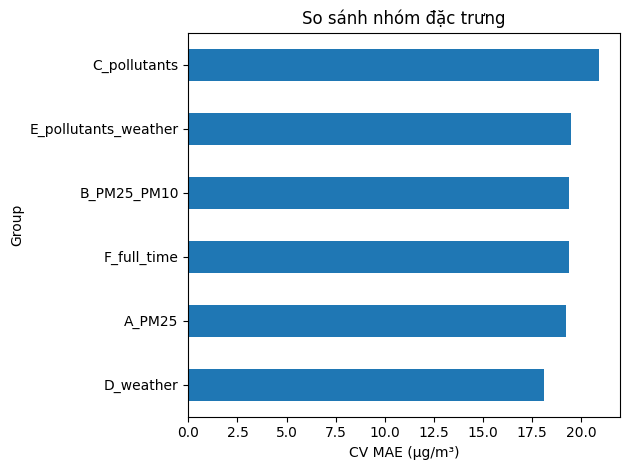

In [37]:
group_results.plot.barh(x='Group', y='CV_MAE', legend=False)
plt.xlabel('CV MAE (µg/m³)')
plt.title('So sánh nhóm đặc trưng')
plt.tight_layout()
plt.show()

## IX. Thử thêm các feature còn thiếu

Các cặp sin/cos được xét cùng nhau. Chỉ giữ khi MAE giảm ít nhất 0,05 µg/m³; đây là quy tắc lựa chọn, không phải kiểm định thống kê.

In [ ]:
# Mỗi block là một nhóm được xét thêm/bỏ cùng nhau (cặp sin/cos phải đi cùng)
feature_blocks = (
    [[f] for f in pollutants + weather_base]
    + [['wind_sin', 'wind_cos'],
       ['wind_calm'],
       ['wind_roll6'],
       ['Pressure_anom_24'],
       ['Soil Moisture'],
       ['Boundary Layer Height'],
       ['Wind Speed 10m'],
       ['Fire Count 100km 3d'],
       ['Fire FRP 100km 7d'],
       ['PM10_PM25_ratio'],
       ['hours_since_rain'],
       ['rain_24h_sum'],
       ['Accumulated Hours of Rain'],
       ['IsHoliday'],
       ['hour_sin', 'hour_cos'],
       ['dow_sin', 'dow_cos'],
       ['month_sin', 'month_cos']]
)
print('Số block:', len(feature_blocks))

In [ ]:
add_rows = []

for block in feature_blocks:
    missing = [f for f in block if f not in selected_features]
    if not missing:
        continue

    trial = selected_features + missing
    score, _ = evaluate(trial, 48, 'ADD_' + '_'.join(missing))
    add_rows.append({
        'Block': '|'.join(missing),
        'N_added': len(missing),
        'CV_MAE': score,
        'Gain': current_score - score,
    })

add_rows = sorted(add_rows, key=lambda r: r['CV_MAE'])
add_table = pd.DataFrame(add_rows)
display(add_table.sort_values('CV_MAE').head(10))

In [40]:
for row in [r for r in add_rows if r['Gain'] >= MIN_GAIN][:3]:
    trial = selected_features + [f for f in row['Block'] if f not in selected_features]
    score, _ = evaluate(trial, 48, 'CONFIRM_ADD_' + '_'.join(row['Block']))
    if current_score - score >= MIN_GAIN:
        selected_features, current_score = (trial, score)
print('Features sau thêm:', selected_features)

Features sau thêm: ['PM25', 'Temperature', 'Relative Humidity', 'Precipitation', 'Clouds', 'Pressure', 'UV Index', 'Wind Speed', 'Solar Radiation', 'wind_sin', 'wind_cos']


## X. Chọn số giờ lịch sử

In [41]:
window_rows = []
for w in WINDOWS:
    score, _ = evaluate(selected_features, w, f'WINDOW_{w}')
    window_rows.append({'Window': w, 'CV_MAE': score})
window_results = pd.DataFrame(window_rows).sort_values(['CV_MAE', 'Window'])
display(window_results)
best_window = int(window_results.iloc[0].Window)
current_score = float(window_results.iloc[0].CV_MAE)

WINDOW_24 | window: 24 | fold: 1 | seed: 42
MAE: 20.848 | Epoch: 30
WINDOW_24 | window: 24 | fold: 1 | seed: 123
MAE: 20.714 | Epoch: 24
WINDOW_24 | window: 24 | fold: 2 | seed: 42
MAE: 11.941 | Epoch: 21
WINDOW_24 | window: 24 | fold: 2 | seed: 123
MAE: 11.908 | Epoch: 26
WINDOW_24 | window: 24 | fold: 3 | seed: 42
MAE: 21.565 | Epoch: 27
WINDOW_24 | window: 24 | fold: 3 | seed: 123
MAE: 21.474 | Epoch: 17
WINDOW_48 | window: 48 | fold: 1 | seed: 42
MAE: 20.89 | Epoch: 30
WINDOW_48 | window: 48 | fold: 1 | seed: 123
MAE: 20.618 | Epoch: 24
WINDOW_48 | window: 48 | fold: 2 | seed: 42
MAE: 11.945 | Epoch: 21
WINDOW_48 | window: 48 | fold: 2 | seed: 123
MAE: 11.921 | Epoch: 26
WINDOW_48 | window: 48 | fold: 3 | seed: 42
MAE: 21.682 | Epoch: 19
WINDOW_48 | window: 48 | fold: 3 | seed: 123
MAE: 21.701 | Epoch: 27
WINDOW_72 | window: 72 | fold: 1 | seed: 42
MAE: 20.887 | Epoch: 30
WINDOW_72 | window: 72 | fold: 1 | seed: 123
MAE: 20.603 | Epoch: 24
WINDOW_72 | window: 72 | fold: 2 | seed: 4

,Window,CV_MAE
0,24,18.075174
3,96,18.115754
1,48,18.125952
2,72,18.127933


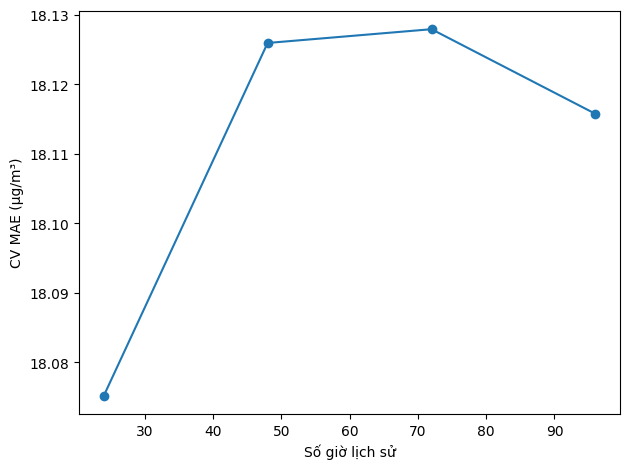

In [42]:
window_results.sort_values('Window').plot(x='Window', y='CV_MAE', marker='o', legend=False)
plt.xlabel('Số giờ lịch sử')
plt.ylabel('CV MAE (µg/m³)')
plt.tight_layout()
plt.show()

## XI. Thử bỏ các feature không giúp ích

In [43]:
removal_rows = []
for block in feature_blocks:
    removed = [f for f in block if f in selected_features]
    if not removed:
        continue
    trial = [f for f in selected_features if f not in removed]
    old_score = current_score
    score, _ = evaluate(trial, best_window, 'REMOVE_' + '_'.join(removed))
    accept = score <= old_score
    if accept:
        selected_features, current_score = (trial, score)
    removal_rows.append({'Removed': '|'.join(removed), 'Before_MAE': old_score, 'Trial_MAE': score, 'Delta': score - old_score, 'Accepted': accept})
display(pd.DataFrame(removal_rows))

REMOVE_Temperature | window: 24 | fold: 1 | seed: 42
MAE: 20.723 | Epoch: 28
REMOVE_Temperature | window: 24 | fold: 1 | seed: 123
MAE: 20.666 | Epoch: 27
REMOVE_Temperature | window: 24 | fold: 2 | seed: 42
MAE: 12.059 | Epoch: 15
REMOVE_Temperature | window: 24 | fold: 2 | seed: 123
MAE: 11.979 | Epoch: 15
REMOVE_Temperature | window: 24 | fold: 3 | seed: 42
MAE: 21.613 | Epoch: 26
REMOVE_Temperature | window: 24 | fold: 3 | seed: 123
MAE: 21.734 | Epoch: 22
REMOVE_Relative Humidity | window: 24 | fold: 1 | seed: 42
MAE: 20.861 | Epoch: 24
REMOVE_Relative Humidity | window: 24 | fold: 1 | seed: 123
MAE: 20.713 | Epoch: 28
REMOVE_Relative Humidity | window: 24 | fold: 2 | seed: 42
MAE: 12.017 | Epoch: 15
REMOVE_Relative Humidity | window: 24 | fold: 2 | seed: 123
MAE: 12.04 | Epoch: 12
REMOVE_Relative Humidity | window: 24 | fold: 3 | seed: 42
MAE: 21.707 | Epoch: 23
REMOVE_Relative Humidity | window: 24 | fold: 3 | seed: 123
MAE: 21.698 | Epoch: 24
REMOVE_Precipitation | window: 24 |

,Removed,Before_MAE,Trial_MAE,Delta,Accepted
0,Temperature,18.075174,18.129094,0.053921,False
1,Relative Humidity,18.075174,18.172530,0.097356,False
2,Precipitation,18.075174,18.152196,0.077023,False
3,Clouds,18.075174,18.090049,0.014875,False
4,Pressure,18.075174,18.034029,-0.041145,True
5,UV Index,18.034029,18.000510,-0.033519,True
6,Wind Speed,18.000510,18.190137,0.189627,False
7,Solar Radiation,18.000510,18.167539,0.167029,False
8,wind_sin|wind_cos,18.000510,18.022280,0.021770,False


## XII. Tổng hợp và lưu cấu hình

Đây là điểm CV dùng chọn cấu hình, chưa phải điểm kiểm tra cuối độc lập. Các model sau phải đọc cấu hình mới, không dùng lại fallback 9 feature/72 giờ.

In [44]:
# all_results = pd.DataFrame(experiment_rows)
# final_key = '|'.join(selected_features)
# final_row = all_results[
#     (all_results['Features'] == final_key) &
#     (all_results['Window'] == best_window)
# ].iloc[-1]
# # final_rows = pd.read_csv(SAVE_DIR + '/' + final_row['Experiment'] + '_details.csv')
# # display(final_rows)
# # final_rows.to_csv(SAVE_DIR + '/selected_cv_metrics.csv', index=False)

# print('Feature được chọn:', selected_features)
# print('Window được chọn:', best_window)
# print('CV MAE:', final_row['CV_MAE'])
final_cv_mae = float(current_score)

print('Feature được chọn:', selected_features)
print('Window được chọn:', best_window)
print('CV MAE:', round(final_cv_mae, 4))

Feature được chọn: ['PM25', 'Temperature', 'Relative Humidity', 'Precipitation', 'Clouds', 'Wind Speed', 'Solar Radiation', 'wind_sin', 'wind_cos']
Window được chọn: 24
CV MAE: 18.00050973892212


In [ ]:
config = {
    'selected_features': selected_features,
    'input_window': int(best_window),
    'horizons': HORIZONS,
    'target_column': 'PM25_target',
    'train_end': str(TRAIN_END),
    'validation_start': str(VAL_START),
    'validation_end': str(VAL_END),
    'test_start': str(TEST_START),

    'data_source': 'feature_data.csv',
    'total_candidates': len(ALL_FEATURES),
    'n_selected': len(selected_features),
    'selected_external': [f for f in selected_features if f in external],
    'selected_derived': [f for f in selected_features if f in derived],
    'selected_weather_derived': [f for f in selected_features if f in weather_derived],

    'selection_scope': 'CV trong Train 70%',
    'selection_cv_mae': final_cv_mae,

    'test_used_for_selection': False,
    'test_previously_explored_in_eda': True,
    'validation_previously_used_for_selection': True,
}

config_path = os.path.join(SAVE_DIR, 'feature_config.json')
with open(config_path, 'w', encoding='utf-8') as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print('Đã lưu:', config_path)
print('Feature được chọn:', len(selected_features), '/', len(ALL_FEATURES))
print('Từ dữ liệu ngoài     :', config['selected_external'])
print('Từ dẫn xuất khí tượng:', config['selected_weather_derived'])
print('Từ dẫn xuất khác     :', config['selected_derived'])